# 11 · Model 0 (SASRec) training diagnostics

Analysis of the Part D grid search and the repeat runs of the winning configuration.
This notebook **only reads** finished run folders; it does not train, change any run file, or touch the test split.

### What it does
1. Loads every run folder (`history.csv`, `summary.json`, `run_config.json`) and identifies each run from its
   `run_config.json`, not from its folder name.
2. Checks that all runs are comparable (same data, code, users and fixed settings).
3. **Confirms early stopping worked** in every run.
4. Plots the **training loss** and **validation NDCG@10** per epoch for the 8 grid configurations.
5. Compares the 8 configurations and the 3 seeds of the winner.
6. Records the **final training configuration** that achieved the best validation score.

### How to run (Google Colab)
1. Open this notebook in Colab and choose **Runtime → Run all**. No GPU is needed, and nothing has to be installed.
2. Allow access when Colab asks to connect to Google Drive.
3. The whole notebook takes about a minute.

If the first code cell says the run folder was not found, the shared `298A` folder is not in your **My Drive** yet:
in Google Drive open **Shared with me**, right-click `298A`, choose **Organize → Add shortcut**, add it to My Drive,
then run the notebook again.

### Input (read only)
The Part D run folder on the shared Drive, written by notebook 10:
```
/content/drive/MyDrive/298A/part_d_grid_results/grid_full_20261107T200443Z_69f3bc0e/
  run_00_seed_42/ … run_07_seed_42/     8 grid configurations, tuning seed 42
  winner_repeats/seed_43/, seed_44/     the winning configuration, repeated
```
From each run folder the notebook reads only `history.csv`, `summary.json` and `run_config.json` (no checkpoints).
It finds the runs by itself, so the subfolder names do not matter.

### Output (saved to Drive)
Everything is saved in a **separate folder**, `298A/model0_training_diagnostics/` (created if it does not exist).
The run folder above is only read; nothing in it is changed. Running again overwrites the files below.

| File | Contents |
|---|---|
| `11_train_loss_grid.png` | Training loss per epoch, 8 grid configurations |
| `11_val_ndcg10_grid.png` | Validation NDCG@10 per epoch, 8 grid configurations |
| `11_grid_ranking.png`, `11_grid_ranking.csv` | The 8 configurations ranked by best validation NDCG@10 |
| `11_winner_seeds.png` | The winning configuration over seeds 42, 43, 44 |
| `11_early_stopping_checks.csv` | The early-stopping check for every run |
| `11_final_training_config.json` | The final training configuration with its validation scores |
| `11_summary.md` | The written summary (section 8) |

To use other folders, change `RUNS_DIR` or `OUT_DIR` in the first code cell.

All scores are **validation** scores (full catalog, history masked, frozen `rec_eval.py`). Test results belong to Part E.

In [1]:
import os, sys, json, itertools, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- Paths: change these two lines to use other folders -------------------------------------------------------
RUNS_DIR = '/content/drive/MyDrive/298A/part_d_grid_results/grid_full_20261107T200443Z_69f3bc0e'   # read
OUT_DIR = '/content/drive/MyDrive/298A/model0_training_diagnostics'                                  # write
# ------------------------------------------------------------------------------------------------------------------
RUNS_DIR = Path(os.environ.get('RUNS_DIR', RUNS_DIR))          # environment variables override, for local testing
OUT_DIR = Path(os.environ.get('DIAGNOSTICS_OUT', OUT_DIR))

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')

if OUT_DIR.resolve() == RUNS_DIR.resolve() or RUNS_DIR.resolve() in OUT_DIR.resolve().parents:
    raise ValueError('OUT_DIR must be outside the run folder, so the original run files stay untouched.')
if not RUNS_DIR.is_dir():
    raise FileNotFoundError(
        f'Run folder not found: {RUNS_DIR}\n'
        'If 298A is only under "Shared with me" in Google Drive, right-click it, choose Organize > Add shortcut, '
        'add it to My Drive, then run the notebook again.')
try:
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    (OUT_DIR / '.write_test').write_text('ok')
    (OUT_DIR / '.write_test').unlink()
except OSError as e:
    raise PermissionError(
        f'Cannot save results to {OUT_DIR} ({e}).\n'
        'You probably have view-only access to this folder. Ask the folder owner for edit access, or set OUT_DIR '
        "to a folder in your own Drive, for example '/content/drive/MyDrive/model0_diagnostics'.") from None

# Grid search space from configs/config.json, in the order src.training.config.expand_grid uses
# (itertools.product over hidden_size, dropout, learning_rate). This fixes each run's grid index.
SEARCH = {'hidden_size': [64, 128], 'dropout': [0.2, 0.5], 'learning_rate': [0.001, 0.0005]}
GRID_ORDER = list(itertools.product(*SEARCH.values()))
TUNING_SEED = 42
POPULARITY_VAL_NDCG10 = 0.0142   # popularity baseline, validation, from sequence_dataloader.ipynb section 5c

# Chart style: thin lines, recessive grid and axes, text in text colours (never the series colour).
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, INK_2, MUTED, GRID_C, SURFACE = '#0b0b0b', '#52514e', '#8a8984', '#e6e5e1', '#fcfcfb'
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b5b4ae',
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': GRID_C, 'grid.linewidth': 0.6,
    'axes.titlesize': 10, 'axes.titleweight': 'bold', 'axes.labelsize': 9, 'axes.labelcolor': INK_2,
    'xtick.labelsize': 8, 'ytick.labelsize': 8, 'xtick.color': INK_2, 'ytick.color': INK_2,
    'text.color': INK, 'legend.fontsize': 8, 'legend.frameon': False, 'lines.linewidth': 2,
})
pd.set_option('display.width', 200, 'display.max_columns', 30, 'display.max_colwidth', None)

def savefig(fig, name):
    fig.savefig(OUT_DIR / f'{name}.png', bbox_inches='tight')
    plt.show()

print('Reading runs from :', RUNS_DIR)
print('Saving results to :', OUT_DIR)

Mounted at /content/drive
Reading runs from : /content/drive/MyDrive/298A/part_d_grid_results/grid_full_20261107T200443Z_69f3bc0e
Saving results to : /content/drive/MyDrive/298A/model0_training_diagnostics


## 1. Load the runs
Every folder below `RUNS_DIR` that contains a `history.csv` is a candidate. Only Model 0 training runs
(`purpose = model0_single_config_training`) are kept; anything else (for example a development smoke run) is listed
and skipped. Each (configuration, seed) pair must appear exactly once.

In [2]:
runs, skipped = [], []
for h_path in sorted(RUNS_DIR.rglob('history.csv')):
    d = h_path.parent
    missing = [f for f in ('summary.json', 'run_config.json') if not (d / f).exists()]
    if missing:
        skipped.append((str(d.relative_to(RUNS_DIR)), f'missing {missing}')); continue
    rc = json.loads((d / 'run_config.json').read_text())
    if rc['metadata'].get('purpose') != 'model0_single_config_training':
        skipped.append((str(d.relative_to(RUNS_DIR)), f"purpose = {rc['metadata'].get('purpose')}")); continue
    hp = rc['metadata']['model_hyperparameters']
    key = (hp['hidden_size'], hp['dropout'], hp['learning_rate'])
    runs.append({
        'folder': str(d.relative_to(RUNS_DIR)), 'seed': rc['training']['seed'], 'grid_index': GRID_ORDER.index(key),
        'hidden_size': key[0], 'dropout': key[1], 'learning_rate': key[2],
        'history': pd.read_csv(h_path), 'summary': json.loads((d / 'summary.json').read_text()), 'config': rc,
    })

for s in skipped:
    print('skipped:', *s)
pairs = [(r['grid_index'], r['seed']) for r in runs]
assert len(pairs) == len(set(pairs)), 'The same configuration and seed appear in more than one folder'

grid = sorted([r for r in runs if r['seed'] == TUNING_SEED], key=lambda r: r['grid_index'])
assert [r['grid_index'] for r in grid] == list(range(len(GRID_ORDER))), 'Expected all 8 grid configurations at seed 42'

overview = pd.DataFrame([{k: r[k] for k in ('grid_index', 'seed', 'hidden_size', 'dropout', 'learning_rate', 'folder')}
                         | {'epochs_run': len(r['history'])} for r in runs]).sort_values(['seed', 'grid_index'])
print(f'{len(runs)} runs loaded: {len(grid)} grid runs (seed {TUNING_SEED}) + {len(runs) - len(grid)} repeat runs')
overview.reset_index(drop=True)

10 runs loaded: 8 grid runs (seed 42) + 2 repeat runs


,grid_index,seed,hidden_size,dropout,learning_rate,folder,epochs_run
0,0,42,64,0.2,0.0010,run_00_seed_42,15
1,1,42,64,0.2,0.0005,run_01_seed_42,18
2,2,42,64,0.5,0.0010,run_02_seed_42,17
3,3,42,64,0.5,0.0005,run_03_seed_42,22
4,4,42,128,0.2,0.0010,run_04_seed_42,14
5,5,42,128,0.2,0.0005,run_05_seed_42,16
6,6,42,128,0.5,0.0010,run_06_seed_42,16
7,7,42,128,0.5,0.0005,run_07_seed_42,17
8,7,43,128,0.5,0.0005,winner_repeats/seed_43,19
9,7,44,128,0.5,0.0005,winner_repeats/seed_44,18


## 2. Are the runs comparable?
A fair comparison needs every run to use the same frozen data, the same code, all users, and the same fixed
settings; only the three searched hyperparameters (and the seed) may differ. Validation must be full-catalog and
no run may have evaluated the test split.

In [3]:
def fixed_settings(r):
    t, m = r['config']['training'], r['config']['metadata']
    return {
        'train_users': m['train_users'], 'validation_users': m['validation_users'],
        'batch_size': m['batch_size'], 'layers': m['model_layers'], 'heads': m['model_heads'],
        'max_seq_len': m['max_seq_len'], 'sliding_window': m['sliding_window'],
        'optimizer': t['optimizer'], 'weight_decay': t['weight_decay'], 'max_epochs': t['epochs'],
        'patience': t['patience'], 'min_delta': t['min_delta'], 'grad_clip_norm': t['grad_clip_norm'],
        'lr_schedule': 'none' if t['lr_step_size'] is None and t['lr_gamma'] is None else f"step {t['lr_step_size']}",
        'selection': f"{m['selection_split']} {m['selection_metric']}, sampled={m['sampled']}",
        'data_manifest': m['manifest_sha256'][:12],
        'source_code': hashlib.sha256(json.dumps(m['source_sha256'], sort_keys=True).encode()).hexdigest()[:12],
        'test_evaluated': m['test_evaluated'] or r['summary']['test_evaluated'],
    }

fixed = pd.DataFrame([fixed_settings(r) for r in runs])
varying = [c for c in fixed if fixed[c].nunique() > 1]
check_rows = [
    ('All runs use every training and validation user (56,017)',
     bool((fixed.train_users == 56017).all() and (fixed.validation_users == 56017).all())),
    ('Same fixed settings, data and code in every run', not varying),
    ('Selection on full-catalog validation NDCG@10', bool((fixed.selection == 'val NDCG@10, sampled=False').all())),
    ('No run evaluated the test split', not fixed.test_evaluated.any()),
    ('Every run finished (summary status PASS)', all(r['summary']['status'] == 'PASS' for r in runs)),
]
for name, ok in check_rows:
    print(('PASS ' if ok else 'FAIL ') + name)
if varying:
    print('Settings that differ between runs:', varying)
print()
fixed.iloc[[0]].T.rename(columns={0: 'value in every run'})

PASS All runs use every training and validation user (56,017)
PASS Same fixed settings, data and code in every run
PASS Selection on full-catalog validation NDCG@10
PASS No run evaluated the test split
PASS Every run finished (summary status PASS)



,value in every run
train_users,56017
validation_users,56017
batch_size,128
layers,2
heads,1
max_seq_len,50
sliding_window,False
optimizer,Adam
weight_decay,0.0
max_epochs,200


## 3. Did early stopping work?
The training loop (`src/training/trainer.py`) validates after every epoch, keeps the checkpoint with the highest
validation NDCG@10 (a tie does not replace it), and stops once NDCG@10 has not improved by more than `min_delta` for
`patience` epochs in a row. For each run this cell recomputes everything from `history.csv` and checks:

- **best epoch** = the first epoch with the highest validation NDCG@10, and it matches `summary.json`
- **stopped on time**: the run ended exactly `patience` epochs after its best epoch, before the epoch budget
- **`improved` flags**: an epoch is flagged as improved only when it beats every earlier epoch
- the saved best score in `summary.json` equals the score in `history.csv`

In [4]:
def early_stopping_report(r):
    h, s = r['history'], r['summary']
    t = r['config']['training']
    ndcg = h['val_NDCG@10'].to_numpy()
    best = int(ndcg.argmax()) + 1                       # first epoch with the maximum
    prev_max = np.r_[-np.inf, np.maximum.accumulate(ndcg)[:-1]]
    flags_ok = bool((h['improved'].to_numpy() == (ndcg > prev_max)).all())
    # The stopping counter also uses min_delta; with min_delta = 0 it equals "epochs since the best epoch".
    stop_score, bad = -np.inf, 0
    for v in ndcg:
        stop_score, bad = (v, 0) if v > stop_score + t['min_delta'] else (stop_score, bad + 1)
    checks = {
        'best epoch correct': best == s['best_epoch'],
        'best score saved': abs(ndcg.max() - s['best_validation_NDCG@10']) < 1e-12,
        'stopped on time': (bad == t['patience'] and bad_streak_ends_run(ndcg, t)
                            and s['early_stopped'] and len(h) == s['epochs_completed'] < t['epochs']),
        'improved flags': flags_ok,
        'epochs 1..N': list(h['epoch']) == list(range(1, len(h) + 1)),
    }
    return {'grid_index': r['grid_index'], 'seed': r['seed'], 'best_epoch': best, 'stopped_after_epoch': len(h),
            'epochs_after_best': len(h) - best, 'patience': t['patience'], 'max_epochs': t['epochs'],
            'best_val_NDCG@10': ndcg.max(), 'final_val_NDCG@10': ndcg[-1],
            'val_drop_after_best_%': 100 * (ndcg.max() - ndcg[-1]) / ndcg.max(), **checks, 'ALL PASS': all(checks.values())}

def bad_streak_ends_run(ndcg, t):
    # Patience must be reached at the last epoch and not before it (otherwise the run should have stopped earlier).
    stop_score, bad = -np.inf, 0
    for i, v in enumerate(ndcg):
        stop_score, bad = (v, 0) if v > stop_score + t['min_delta'] else (stop_score, bad + 1)
        if bad >= t['patience'] and i < len(ndcg) - 1:
            return False
    return True

es = pd.DataFrame([early_stopping_report(r) for r in runs]).sort_values(['seed', 'grid_index']).reset_index(drop=True)
print('Early stopping:', 'PASS in all runs' if es['ALL PASS'].all() else 'FAILED - see the table')
es.to_csv(OUT_DIR / '11_early_stopping_checks.csv', index=False)
es.style.format({'best_val_NDCG@10': '{:.4f}', 'final_val_NDCG@10': '{:.4f}', 'val_drop_after_best_%': '{:.1f}'}).hide(axis='index')

Early stopping: PASS in all runs


grid_index,seed,best_epoch,stopped_after_epoch,epochs_after_best,patience,max_epochs,best_val_NDCG@10,final_val_NDCG@10,val_drop_after_best_%,best epoch correct,best score saved,stopped on time,improved flags,epochs 1..N,ALL PASS
0,42,5,15,10,10,200,0.0418,0.0364,12.8,True,True,True,True,True,True
1,42,8,18,10,10,200,0.0422,0.0368,12.8,True,True,True,True,True,True
2,42,7,17,10,10,200,0.0438,0.0421,3.9,True,True,True,True,True,True
3,42,12,22,10,10,200,0.0441,0.0424,3.9,True,True,True,True,True,True
4,42,4,14,10,10,200,0.0430,0.0301,30.0,True,True,True,True,True,True
5,42,6,16,10,10,200,0.0442,0.0290,34.3,True,True,True,True,True,True
6,42,6,16,10,10,200,0.0452,0.0422,6.6,True,True,True,True,True,True
7,42,7,17,10,10,200,0.0456,0.0410,10.0,True,True,True,True,True,True
7,43,9,19,10,10,200,0.0453,0.0410,9.3,True,True,True,True,True,True
7,44,8,18,10,10,200,0.0454,0.0407,10.4,True,True,True,True,True,True


## 4. Training loss and validation NDCG@10 per epoch (8 grid configurations, seed 42)
One panel per model size and dropout; the two lines in each panel are the two learning rates. The dot marks the
**best epoch** (the checkpoint that was kept); each line ends where early stopping stopped the run.

Training loss is the average cross-entropy over each epoch, measured in training mode (dropout switched on). It is
therefore only comparable between runs with the same dropout; a lower loss at dropout 0.2 than at 0.5 is partly just
less dropout noise.

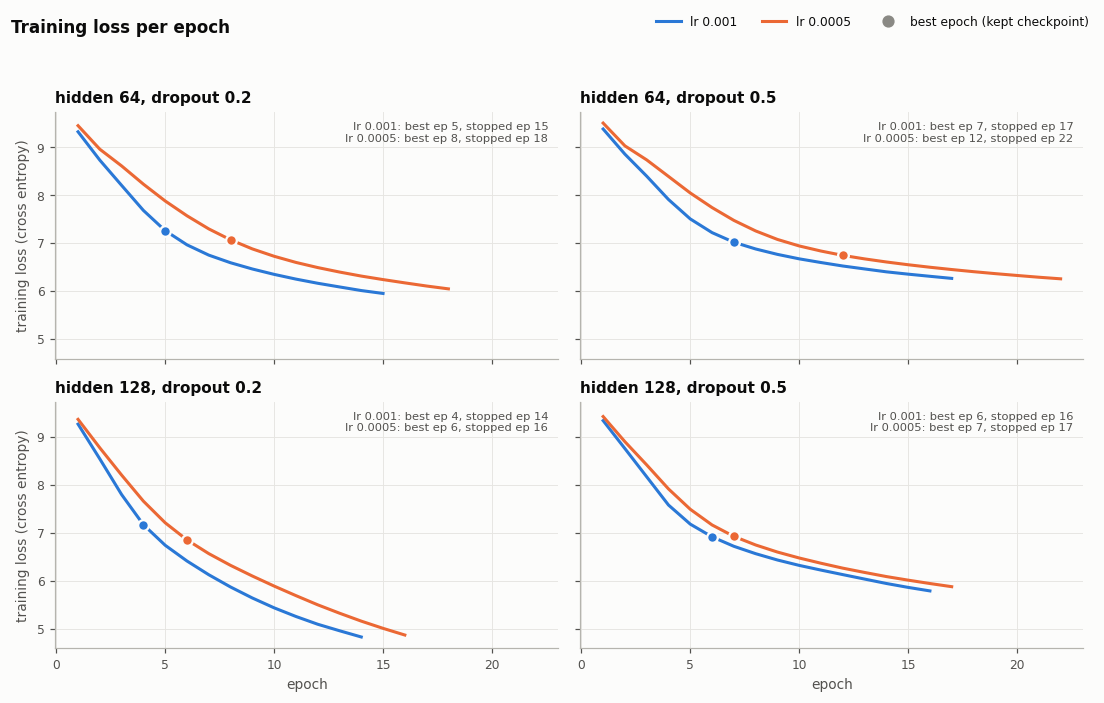

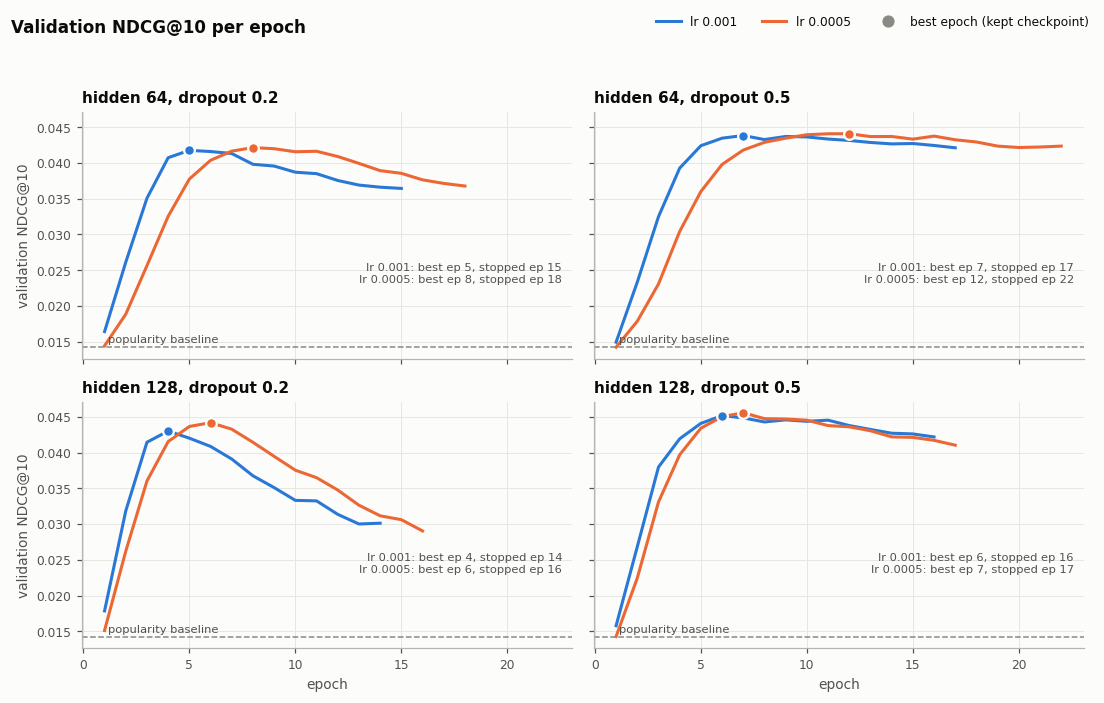

In [5]:
LR_STYLE = {0.001: (BLUE, 'lr 0.001'), 0.0005: (ORANGE, 'lr 0.0005')}
def panel_title(h, d):
    return f'hidden {h}, dropout {d}'

def grid_panels(column, ylabel, title, name, baseline=None):
    fig, axes = plt.subplots(2, 2, figsize=(10, 6.4), sharex=True, sharey=True)
    for ax, (h, d) in zip(axes.flat, itertools.product(SEARCH['hidden_size'], SEARCH['dropout'])):
        notes = []
        for r in [r for r in grid if r['hidden_size'] == h and r['dropout'] == d]:
            hist, colour = r['history'], LR_STYLE[r['learning_rate']][0]
            best = int(hist['val_NDCG@10'].idxmax())
            ax.plot(hist['epoch'], hist[column], color=colour, label=LR_STYLE[r['learning_rate']][1])
            ax.plot(hist['epoch'][best], hist[column][best], 'o', ms=7, color=colour, mec=SURFACE, mew=1.5, zorder=3)
            notes.append(f"{LR_STYLE[r['learning_rate']][1]}: best ep {best + 1}, stopped ep {len(hist)}")
        if baseline is not None:
            ax.axhline(baseline, color=MUTED, lw=1, ls='--')
            ax.annotate('popularity baseline', (1, baseline), xytext=(2, 3), textcoords='offset points',
                        fontsize=7.5, color=INK_2)
        ax.set_title(panel_title(h, d), loc='left')
        ax.text(0.98, 0.96 if column == 'train_loss' else 0.30, '\n'.join(notes), transform=ax.transAxes,
                ha='right', va='top' if column == 'train_loss' else 'bottom', fontsize=7.5, color=INK_2)
    for ax in axes[-1]: ax.set_xlabel('epoch')
    for ax in axes[:, 0]: ax.set_ylabel(ylabel)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    handles.append(plt.Line2D([], [], marker='o', ls='', color=MUTED, ms=7)); labels.append('best epoch (kept checkpoint)')
    fig.legend(handles, labels, loc='upper right', ncol=3, bbox_to_anchor=(1, 1.0))
    fig.suptitle(title, x=0.01, ha='left', fontsize=11, fontweight='bold')
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    savefig(fig, name)

grid_panels('train_loss', 'training loss (cross entropy)', 'Training loss per epoch', '11_train_loss_grid')
grid_panels('val_NDCG@10', 'validation NDCG@10', 'Validation NDCG@10 per epoch', '11_val_ndcg10_grid',
            baseline=POPULARITY_VAL_NDCG10)

## 5. Which configuration won?
Best validation NDCG@10 of each configuration (seed 42), highest first. Selection used validation NDCG@10 only;
an exact tie would go to the configuration listed first in the grid.

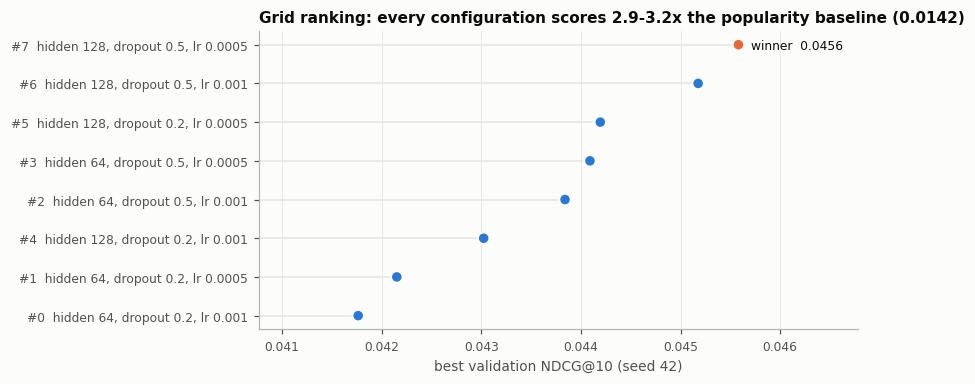

rank,grid_index,hidden_size,dropout,learning_rate,best_epoch,epochs_run,NDCG@10,Recall@10,NDCG@20,Recall@20,MRR,final_train_loss,minutes
1,7,128,0.500000,0.000500,7,17,0.0456,0.0769,0.0526,0.1046,0.0415,5.875,6.3
2,6,128,0.500000,0.001000,6,16,0.0452,0.0767,0.0524,0.1053,0.0412,5.787,6.2
3,5,128,0.200000,0.000500,6,16,0.0442,0.0759,0.0513,0.1042,0.0401,4.866,5.9
4,3,64,0.500000,0.000500,12,22,0.0441,0.0743,0.0508,0.1010,0.0402,6.254,6.6
5,2,64,0.500000,0.001000,7,17,0.0438,0.0747,0.0507,0.1020,0.0398,6.263,5.1
6,4,128,0.200000,0.001000,4,14,0.0430,0.0752,0.0503,0.1041,0.0390,4.826,5.1
7,1,64,0.200000,0.000500,8,18,0.0422,0.0720,0.0492,0.1000,0.0386,6.045,5.3
8,0,64,0.200000,0.001000,5,15,0.0418,0.0720,0.0490,0.1010,0.0381,5.949,4.4


In [6]:
ranking = pd.DataFrame([{
    'grid_index': r['grid_index'], 'hidden_size': r['hidden_size'], 'dropout': r['dropout'],
    'learning_rate': r['learning_rate'], 'best_epoch': r['summary']['best_epoch'],
    'epochs_run': len(r['history']),
    **{m: r['history'][f'val_{m}'].iloc[r['summary']['best_epoch'] - 1]
       for m in ('NDCG@10', 'Recall@10', 'NDCG@20', 'Recall@20', 'MRR')},
    'final_train_loss': r['history']['train_loss'].iloc[-1],
    'minutes': r['history']['seconds'].sum() / 60,
} for r in grid]).sort_values(['NDCG@10', 'grid_index'], ascending=[False, True]).reset_index(drop=True)
ranking.insert(0, 'rank', range(1, len(ranking) + 1))
winner_index = int(ranking.loc[0, 'grid_index'])

fig, ax = plt.subplots(figsize=(8, 3.6))
plot = ranking.iloc[::-1]
labels = [f"#{g}  hidden {h}, dropout {d}, lr {lr}" for g, h, d, lr in
          zip(plot.grid_index, plot.hidden_size, plot.dropout, plot.learning_rate)]
colours = [ORANGE if g == winner_index else BLUE for g in plot.grid_index]
ax.hlines(range(len(plot)), plot['NDCG@10'].min() - 0.001, plot['NDCG@10'], color=GRID_C, lw=1)
ax.scatter(plot['NDCG@10'], range(len(plot)), s=60, c=colours, edgecolors=SURFACE, linewidths=1.5, zorder=3)
ax.set_yticks(range(len(plot)), labels)
ax.grid(axis='y', visible=False)
top = ranking.loc[0]
ax.annotate(f"winner  {top['NDCG@10']:.4f}", (top['NDCG@10'], len(plot) - 1), xytext=(8, -3),
            textcoords='offset points', fontsize=8, color=INK)
ax.set_xlabel('best validation NDCG@10 (seed 42)')
ax.set_xlim(plot['NDCG@10'].min() - 0.001, plot['NDCG@10'].max() + 0.0012)
ax.set_title(f'Grid ranking: every configuration scores {ranking["NDCG@10"].min() / POPULARITY_VAL_NDCG10:.1f}-'
             f'{ranking["NDCG@10"].max() / POPULARITY_VAL_NDCG10:.1f}x the popularity baseline ({POPULARITY_VAL_NDCG10})',
             loc='left')
fig.tight_layout()
savefig(fig, '11_grid_ranking')

ranking.to_csv(OUT_DIR / '11_grid_ranking.csv', index=False)
ranking.style.format({c: '{:.4f}' for c in ['NDCG@10', 'Recall@10', 'NDCG@20', 'Recall@20', 'MRR']}
                     | {'final_train_loss': '{:.3f}', 'minutes': '{:.1f}'}).hide(axis='index')

### Effect of each hyperparameter
Average best validation NDCG@10 over the four configurations that share each value. These are averages over
only four runs at one seed, so treat small differences with care.

In [7]:
effects = pd.concat([
    ranking.groupby(p)['NDCG@10'].mean().rename('mean best val NDCG@10').to_frame()
           .assign(parameter=p).reset_index().rename(columns={p: 'value'})
    for p in SEARCH
])[['parameter', 'value', 'mean best val NDCG@10']]
pairs_better = {
    p: int(sum(ranking.set_index(list(SEARCH)).loc[k_hi, 'NDCG@10'] > ranking.set_index(list(SEARCH)).loc[k_lo, 'NDCG@10']
               for k_lo, k_hi in [(tuple(v if q != p else SEARCH[p][0] for q, v in zip(SEARCH, combo)),
                                   tuple(v if q != p else SEARCH[p][1] for q, v in zip(SEARCH, combo)))
                                  for combo in GRID_ORDER if combo[list(SEARCH).index(p)] == SEARCH[p][0]]))
    for p in SEARCH
}
for p, n in pairs_better.items():
    print(f'{p} = {SEARCH[p][1]} beat {p} = {SEARCH[p][0]} in {n} of 4 matched pairs')
effects.style.format({'mean best val NDCG@10': '{:.4f}'}).hide(axis='index')

hidden_size = 128 beat hidden_size = 64 in 4 of 4 matched pairs
dropout = 0.5 beat dropout = 0.2 in 4 of 4 matched pairs
learning_rate = 0.0005 beat learning_rate = 0.001 in 4 of 4 matched pairs


parameter,value,mean best val NDCG@10
hidden_size,64.000000,0.0430
hidden_size,128.000000,0.0445
dropout,0.200000,0.0428
dropout,0.500000,0.0447
learning_rate,0.000500,0.0440
learning_rate,0.001000,0.0435


## 6. Winning configuration across seeds
The winner (chosen at seed 42) was trained again with seeds 43 and 44 and exactly the same settings. The three seeds'
curves almost overlap, so the result is not a lucky seed. Seed 42 chose the configuration, so the mean below is
slightly optimistic; the unbiased estimate is Part E's test evaluation.

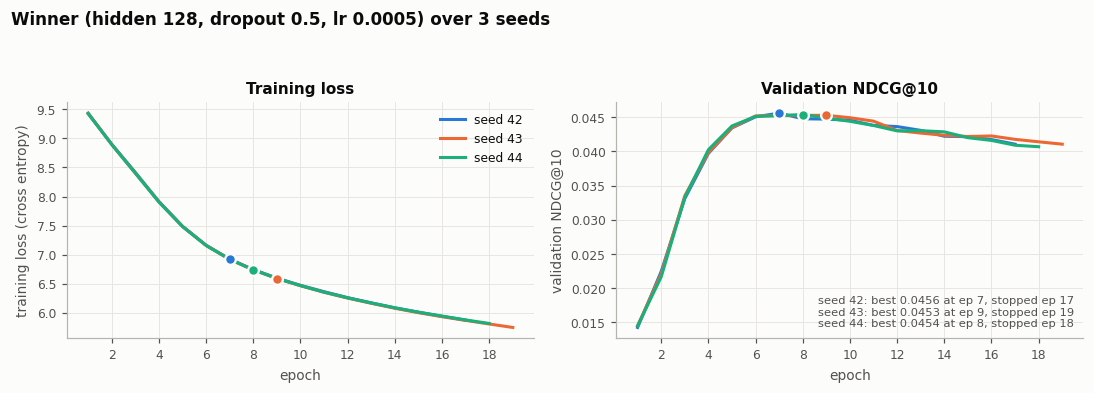

Validation NDCG@10 over seeds: mean 0.045405, sample std 0.000163


,best_epoch,epochs_run,NDCG@10,Recall@10,MRR
42,7,17,0.0456,0.0769,0.0415
43,9,19,0.0453,0.0764,0.0413
44,8,18,0.0454,0.0770,0.0412
mean,,,0.0454,0.0768,0.0413
sample std,,,0.0002,0.0003,0.0002


In [8]:
winner_runs = sorted([r for r in runs if r['grid_index'] == winner_index], key=lambda r: r['seed'])
SEED_COLOURS = [BLUE, ORANGE, AQUA]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharex=True)
for r, colour in zip(winner_runs, SEED_COLOURS):
    h = r['history']; best = int(h['val_NDCG@10'].idxmax())
    for ax, col in zip(axes, ['train_loss', 'val_NDCG@10']):
        ax.plot(h['epoch'], h[col], color=colour, label=f"seed {r['seed']}")
        ax.plot(h['epoch'][best], h[col][best], 'o', ms=7, color=colour, mec=SURFACE, mew=1.5, zorder=3)
w = winner_runs[0]
axes[0].set(title='Training loss', xlabel='epoch', ylabel='training loss (cross entropy)')
axes[1].set(title='Validation NDCG@10', xlabel='epoch', ylabel='validation NDCG@10')
axes[1].text(0.98, 0.04, '\n'.join(
    f"seed {r['seed']}: best {r['history']['val_NDCG@10'].max():.4f} at ep {r['summary']['best_epoch']}, "
    f"stopped ep {len(r['history'])}" for r in winner_runs),
    transform=axes[1].transAxes, ha='right', va='bottom', fontsize=7.5, color=INK_2)
axes[0].legend(loc='upper right')
for ax in axes: ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
fig.suptitle(f"Winner (hidden {w['hidden_size']}, dropout {w['dropout']}, lr {w['learning_rate']}) over "
             f"{len(winner_runs)} seeds", x=0.01, ha='left', fontsize=11, fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.93))
savefig(fig, '11_winner_seeds')

seeds = pd.DataFrame([{'seed': r['seed'], 'best_epoch': r['summary']['best_epoch'], 'epochs_run': len(r['history']),
                       **{m: r['history'][f'val_{m}'].iloc[r['summary']['best_epoch'] - 1]
                          for m in ('NDCG@10', 'Recall@10', 'MRR')}} for r in winner_runs])
agg = seeds[['NDCG@10', 'Recall@10', 'MRR']].agg(['mean', 'std'])   # pandas std uses ddof=1 (sample std)
print('Validation NDCG@10 over seeds: mean {:.6f}, sample std {:.6f}'.format(*agg['NDCG@10']))
pd.concat([seeds.set_index('seed'), agg.rename(index={'mean': 'mean', 'std': 'sample std'})]) \
  .style.format('{:.4f}', subset=['NDCG@10', 'Recall@10', 'MRR']).format('{:.0f}', subset=['best_epoch', 'epochs_run'], na_rep='')

## 7. Final training configuration (best validation score)
The configuration below achieved the highest validation NDCG@10 in the grid. Every value is read from the winning
run's `run_config.json`, so this table is exactly what was run.

In [9]:
w = next(r for r in grid if r['grid_index'] == winner_index)
t, m = w['config']['training'], w['config']['metadata']
best_row = w['history'].iloc[w['summary']['best_epoch'] - 1]
final_config = {
    'Model': 'SASRec (src/models/sasrec.py), causal self-attention, tied item embeddings',
    'Hidden size (searched)': w['hidden_size'],
    'Dropout (searched)': w['dropout'],
    'Learning rate (searched)': w['learning_rate'],
    'Transformer layers': m['model_layers'],
    'Attention heads': m['model_heads'],
    'Max sequence length': m['max_seq_len'],
    'Batch size': m['batch_size'],
    'Optimizer': t['optimizer'],
    'Weight decay': t['weight_decay'],
    'Gradient clipping (max norm)': t['grad_clip_norm'],
    'Learning-rate schedule': 'none' if t['lr_step_size'] is None else f"StepLR({t['lr_step_size']}, {t['lr_gamma']})",
    'Max epochs': t['epochs'],
    'Early stopping': f"patience {t['patience']}, min_delta {t['min_delta']}, on validation NDCG@10",
    'Loss': 'cross entropy over the full catalog, non-padding positions only',
    'Training data': f"{m['train_users']:,} users, one window per user: up to the {m['max_seq_len'] + 1} most recent training items, "
                     f"left-padded (sliding_window={m['sliding_window']})",
    'Tuning seed': t['seed'],
    'Best epoch': w['summary']['best_epoch'],
    'Epochs run (early stopped)': len(w['history']),
    'Validation NDCG@10': f"{best_row['val_NDCG@10']:.4f}",
    'Validation Recall@10': f"{best_row['val_Recall@10']:.4f}",
    'Validation MRR': f"{best_row['val_MRR']:.4f}",
    f'Validation NDCG@10 over seeds {", ".join(str(r["seed"]) for r in winner_runs)}':
        f"{agg.loc['mean', 'NDCG@10']:.4f} ± {agg.loc['std', 'NDCG@10']:.4f} (mean ± sample std)",
    'Run folder': w['folder'],
}
(OUT_DIR / '11_final_training_config.json').write_text(json.dumps(
    {k: (v.item() if hasattr(v, 'item') else v) for k, v in final_config.items()}, indent=2))
pd.Series(final_config, name='value').to_frame()

,value
Model,"SASRec (src/models/sasrec.py), causal self-attention, tied item embeddings"
Hidden size (searched),128
Dropout (searched),0.5
Learning rate (searched),0.0005
Transformer layers,2
Attention heads,1
Max sequence length,50
Batch size,128
Optimizer,Adam
Weight decay,0.0


## 8. Summary

In [10]:
loss_falls = all((r['history']['train_loss'].diff().dropna() < 0).all() for r in runs)
drop = es.set_index(['grid_index', 'seed'])['val_drop_after_best_%']
by_dropout = {d: drop[[(r['grid_index'], r['seed']) for r in runs if r['dropout'] == d]] for d in SEARCH['dropout']}
lines = [
    f"Early stopping worked in all {len(runs)} runs: each stopped exactly {runs[0]['config']['training']['patience']} "
    f"epochs after its best epoch (best epochs {es.best_epoch.min()}-{es.best_epoch.max()}, "
    f"well before the {runs[0]['config']['training']['epochs']}-epoch budget), and summary.json kept the best epoch.",
    f"Training loss fell in every epoch of every run ({loss_falls}), while validation NDCG@10 fell after the best epoch: "
    f"by {by_dropout[0.2].min():.0f}-{by_dropout[0.2].max():.0f}% with dropout 0.2 and by "
    f"{by_dropout[0.5].min():.0f}-{by_dropout[0.5].max():.0f}% with dropout 0.5 by the time each run stopped. "
    f"That is overfitting, strongest with less dropout, and early stopping kept the checkpoint from before it.",
    f"Best configuration: grid #{winner_index} (hidden {w['hidden_size']}, dropout {w['dropout']}, "
    f"lr {w['learning_rate']}), validation NDCG@10 {ranking.loc[0, 'NDCG@10']:.4f} at epoch {w['summary']['best_epoch']}; "
    f"{ranking.loc[0, 'NDCG@10'] / POPULARITY_VAL_NDCG10:.1f}x the popularity baseline.",
    f"Over seeds {', '.join(str(r['seed']) for r in winner_runs)} the winner scored "
    f"{agg.loc['mean', 'NDCG@10']:.4f} ± {agg.loc['std', 'NDCG@10']:.4f}, so the result is stable across seeds.",
    f"Dropout 0.5 beat 0.2 in {pairs_better['dropout']} of 4 matched pairs and hidden 128 beat 64 in "
    f"{pairs_better['hidden_size']} of 4; lr 0.0005 beat 0.001 in {pairs_better['learning_rate']} of 4.",
    f"Grid training time (sum of epoch times): {ranking['minutes'].sum():.1f} minutes.",
]
for line in lines:
    print('- ' + line)
(OUT_DIR / '11_summary.md').write_text(
    '# Model 0 training diagnostics: summary\n\n' + '\n'.join('- ' + l for l in lines) + '\n\n'
    f'Source runs: `{RUNS_DIR}`\n')

expected = ['11_train_loss_grid.png', '11_val_ndcg10_grid.png', '11_grid_ranking.png', '11_grid_ranking.csv',
            '11_winner_seeds.png', '11_early_stopping_checks.csv', '11_final_training_config.json', '11_summary.md']
missing = [f for f in expected if not (OUT_DIR / f).is_file()]
assert not missing, f'Not saved: {missing}'
print(f'\nAll {len(expected)} result files saved to {OUT_DIR}:')
for f in expected:
    print(f'  {f:34s} {(OUT_DIR / f).stat().st_size / 1024:7.1f} KB')

- Early stopping worked in all 10 runs: each stopped exactly 10 epochs after its best epoch (best epochs 4-12, well before the 200-epoch budget), and summary.json kept the best epoch.
- Training loss fell in every epoch of every run (True), while validation NDCG@10 fell after the best epoch: by 13-34% with dropout 0.2 and by 4-10% with dropout 0.5 by the time each run stopped. That is overfitting, strongest with less dropout, and early stopping kept the checkpoint from before it.
- Best configuration: grid #7 (hidden 128, dropout 0.5, lr 0.0005), validation NDCG@10 0.0456 at epoch 7; 3.2x the popularity baseline.
- Over seeds 42, 43, 44 the winner scored 0.0454 ± 0.0002, so the result is stable across seeds.
- Dropout 0.5 beat 0.2 in 4 of 4 matched pairs and hidden 128 beat 64 in 4 of 4; lr 0.0005 beat 0.001 in 4 of 4.
- Grid training time (sum of epoch times): 45.0 minutes.

All 8 result files saved to /content/drive/MyDrive/298A/model0_training_diagnostics:
  11_train_loss_grid.png  